# Climate and Air Quality effect on Public Health in Ancona, Italy
### Team 08 | Mini-Project: Data Analysis and Visualization | Data from : 2021–2023

**About the data.** Our source is `Ancona_Italy_Climate_Report.csv`, containing **500 observations and 17 original columns**. It includes air pollutants (NO₂, O₃, PM10, PM2.5), weather measurements, timestamps and monitoring-station locations. Each row is one monitoring observation, not a patient record.

**Project focus.** We want to understand how pollution varies by time of day, season and monitoring location, and how weather relates to pollutant readings. The goal is to turn these patterns into practical **public-health monitoring priorities**, without claiming that pollution caused particular diseases.

**Our approach.** We use a simple **Extract → Transform → Load (ETL)** workflow, followed by five graphs. We describe what each graph measures, explain the findings and suggest actions.

## 1. Investigation Blueprint

**Problem statement.** Pollution levels are not constant. They may change with the time, season, weather and monitoring location. Public-health and environmental teams need evidence to decide where and when additional monitoring and communication could be useful.

**Strategic question:** How can Ancona use pollution and weather data to prioritize air-quality monitoring and public-health communication?

**Descriptive question 1:** How do NO₂, O₃, PM10 and PM2.5 readings compare at **8 AM and 5 PM**?

**Descriptive question 2:** How do these four pollutants vary across seasons?

**Diagnostic question:** How are humidity, rainfall and wind speed associated with pollutant concentrations?

**Action question 1:** Which monitoring stations show higher average NO₂ and PM2.5 readings?

**Action question 2:** How do monthly O₃ and PM2.5 averages change over the available period?

**Stakeholders and value.** Environmental monitoring teams can plan follow-up measurements; local public-health services can consider when to share general air-quality advice. This is a **monitoring decision**, not a clinical risk prediction.

**Agile analysis plan.** We work in short steps: inspect the source → clean and validate → create each graph → review interpretations as a team → update the notebook and presentation. Each result is checked against the dataset before reporting.

## 2. Python libraries — what we import and why

- **pandas:** read CSV files, clean columns, group observations and calculate averages.
- **numpy:** calculate wind speed from its two directional components.
- **matplotlib:** draw and label our five graphs.
- **seaborn:** make the boxplots and correlation heatmap easier to read.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 3. EXTRACT — Read, inspect and prepare for cleaning

**What we do:** Read the original CSV, check its dimensions and column names, look for missing values and duplicate rows.

**Why:** We should understand the source before changing anything. In particular, a dataset with 500 observations does **not automatically** mean 250 matched 8 AM/5 PM dates. We verify that instead of assuming it.

In [4]:
raw = pd.read_csv("Ancona_Italy_Climate_Report.csv")
print("Dataset size (rows, columns):", raw.shape)
display(raw.head())
print("\nMissing values by column:\n", raw.isna().sum().to_string())
print("\nExact duplicate rows:", raw.duplicated().sum())
print("\nSource column names:\n", raw.columns.tolist())


Dataset size (rows, columns): (500, 17)


,Date,NO2,O3,PM10,PM2.5,Latitude,Longitude,station_name,Wind-Speed (U),Wind-Speed (V),Dewpoint Temp,Soil Temp,Total Percipitation,Vegitation (High),Vegitation (Low),Temp,Relative Humidity
0,9/8/2021 3:00,13.000000,59.00000,27.000000,24.000000,43.612386,13.510830,Ancona Citadella,-0.730325,-1.081928,62.714207,67.132166,0.000004,3.167948,2.838029,66.012029,80.129641
1,9/8/2021 7:00,20.000000,24.00000,21.000000,17.000000,43.633761,13.388042,Falconara Scuola,-0.572462,-0.748527,65.073282,69.795571,0.000050,3.167039,2.839482,69.756535,73.013196
2,9/8/2021 13:00,3.240358,91.46924,22.801860,15.208222,43.450000,13.250000,Ancona CAMS Station 11,0.298122,0.998666,61.538575,77.860864,0.000393,3.160414,2.843312,76.316858,39.235063
3,9/8/2021 13:00,4.791942,92.31479,23.152130,15.664178,43.650000,13.550000,Ancona CAMS Station 4,0.291146,0.997596,59.771993,76.070556,0.000388,3.169392,2.837216,74.547283,39.252518
4,9/8/2021 13:00,2.786918,91.29361,24.183098,14.032757,43.550000,13.150000,Ancona CAMS Station 5,0.301242,1.001407,61.611660,77.946498,0.000394,3.162923,2.843242,76.397263,39.216172



Missing values by column:
 Date                   0
NO2                    0
O3                     0
PM10                   0
PM2.5                  0
Latitude               0
Longitude              0
station_name           0
Wind-Speed (U)         0
Wind-Speed (V)         0
Dewpoint Temp          0
Soil Temp              0
Total Percipitation    0
Vegitation (High)      0
Vegitation (Low)       0
Temp                   0
Relative Humidity      0

Exact duplicate rows: 0

Source column names:
 ['Date', 'NO2', 'O3', 'PM10', 'PM2.5', 'Latitude', 'Longitude', 'station_name', 'Wind-Speed (U)', 'Wind-Speed (V)', 'Dewpoint Temp', 'Soil Temp', 'Total Percipitation', 'Vegitation (High)', 'Vegitation (Low)', 'Temp', 'Relative Humidity']


## 4. TRANSFORM — Data Cleaning

In this step, we prepare the original dataset for analysis.

**What we do:**
- Create a copy of the extracted dataset.
- Remove duplicate records, if any.
- Convert the Date column into datetime format.
- Check the final dataset size.

**Why we do this:**

This ensures that our dataset is ready for analysis.


In [6]:

# Copy the extracted dataset
df = raw.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=["Date"])

# Check the transformed dataset
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

display(df.head())


Dataset shape: (500, 17)
Missing values: 0


,Date,NO2,O3,PM10,PM2.5,Latitude,Longitude,station_name,Wind-Speed (U),Wind-Speed (V),Dewpoint Temp,Soil Temp,Total Percipitation,Vegitation (High),Vegitation (Low),Temp,Relative Humidity
0,2021-09-08 03:00:00,13.000000,59.00000,27.000000,24.000000,43.612386,13.510830,Ancona Citadella,-0.730325,-1.081928,62.714207,67.132166,0.000004,3.167948,2.838029,66.012029,80.129641
1,2021-09-08 07:00:00,20.000000,24.00000,21.000000,17.000000,43.633761,13.388042,Falconara Scuola,-0.572462,-0.748527,65.073282,69.795571,0.000050,3.167039,2.839482,69.756535,73.013196
2,2021-09-08 13:00:00,3.240358,91.46924,22.801860,15.208222,43.450000,13.250000,Ancona CAMS Station 11,0.298122,0.998666,61.538575,77.860864,0.000393,3.160414,2.843312,76.316858,39.235063
3,2021-09-08 13:00:00,4.791942,92.31479,23.152130,15.664178,43.650000,13.550000,Ancona CAMS Station 4,0.291146,0.997596,59.771993,76.070556,0.000388,3.169392,2.837216,74.547283,39.252518
4,2021-09-08 13:00:00,2.786918,91.29361,24.183098,14.032757,43.550000,13.150000,Ancona CAMS Station 5,0.301242,1.001407,61.611660,77.946498,0.000394,3.162923,2.843242,76.397263,39.216172


## 5. LOAD — Save the Cleaned Dataset

After completing the transformation, we save the cleaned dataset as a new CSV file.

**What we do:**
- Save the prepared dataset.
- Keep the original 17 columns.
- Check the total number of observations.

**Why we do this:**

Saving the cleaned dataset makes our analysis reproducible.


In [8]:

# Save the cleaned dataset
df.to_csv("Ancona_Cleaned_Dataset.csv", index=False)

# Check the dataset
print("Cleaned dataset saved successfully!")
print("Total observations:", len(df))
print("Total columns:", len(df.columns))


Cleaned dataset saved successfully!
Total observations: 500
Total columns: 17


## 6. Descriptive Questions


## A. Research Question 1 — Morning vs Evening Pollution

**Research Question:** How do NO2, O3, PM10 and PM2.5 concentrations differ between 8 AM and 5 PM?

### Graph 1 — Grouped Bar Chart

**Why this graph?**

A grouped bar chart helps us compare the average concentrations of four pollutants at two different times.

**What does it show?**

It shows which pollutants have higher average readings in the morning or evening.

**Public Health Importance:**

Understanding pollution differences at different times can help environmental authorities identify periods that may require closer air-quality monitoring.


Number of observations:
Time
8 AM    60
5 PM     8
Name: count, dtype: int64


,NO2,O3,PM10,PM2.5
Time,,,,
8 AM,13.05,49.53,16.91,11.13
5 PM,16.12,73.50,34.50,19.25


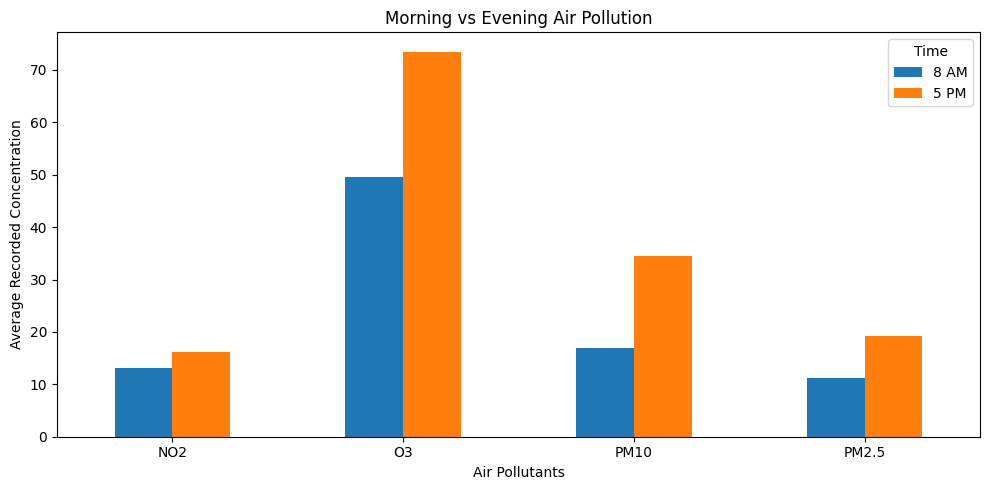

In [10]:

# Select observations at 8 AM and 5 PM
hourly = df[df["Date"].dt.hour.isin([8, 17])].copy()

# Create hour labels
hourly["Time"] = hourly["Date"].dt.hour.map({
    8: "8 AM",
    17: "5 PM"
})

# Calculate average pollution
pollutants = ["NO2", "O3", "PM10", "PM2.5"]

hour_avg = hourly.groupby("Time")[pollutants].mean()
hour_avg = hour_avg.reindex(["8 AM", "5 PM"])

# Display observation counts and averages
print("Number of observations:")
print(hourly["Time"].value_counts())

display(hour_avg.round(2))

# Create grouped bar chart
hour_avg.T.plot(kind="bar", figsize=(10, 5))

plt.title("Morning vs Evening Air Pollution")
plt.xlabel("Air Pollutants")
plt.ylabel("Average Recorded Concentration")
plt.xticks(rotation=0)
plt.legend(title="Time")
plt.tight_layout()
plt.show()



### Graph 1 — Interpretation

The average ozone concentration was higher at 5 PM (73.50) compared with 8 AM (49.53).

However, the dataset contains 60 observations at 8 AM and only 8 observations at 5 PM.

Therefore, this comparison shows differences within our sample, not a confirmed daily pollution pattern.

**Public Health Link:** Monitoring pollution at different times may help identify periods when additional air-quality attention is needed.

## B. Research question 2 — Seasonal pollution patterns
### Graph 2: Seasonal boxplots

**Why this graph?** Boxplots show the typical reading (median), spread and unusual values, not just one average.

**What it shows:** How the distributions of NO₂, O₃, PM10 and PM2.5 vary between winter, spring, summer and autumn. We keep the same four-pollutant seasonal comparison as the earlier notebook.

,NO2,O3,PM10,PM2.5
Season,,,,
Winter,17.82,39.81,20.76,15.83
Spring,11.62,63.05,18.44,12.41
Summer,11.40,77.08,19.20,11.31
Autumn,13.50,45.91,20.15,13.04


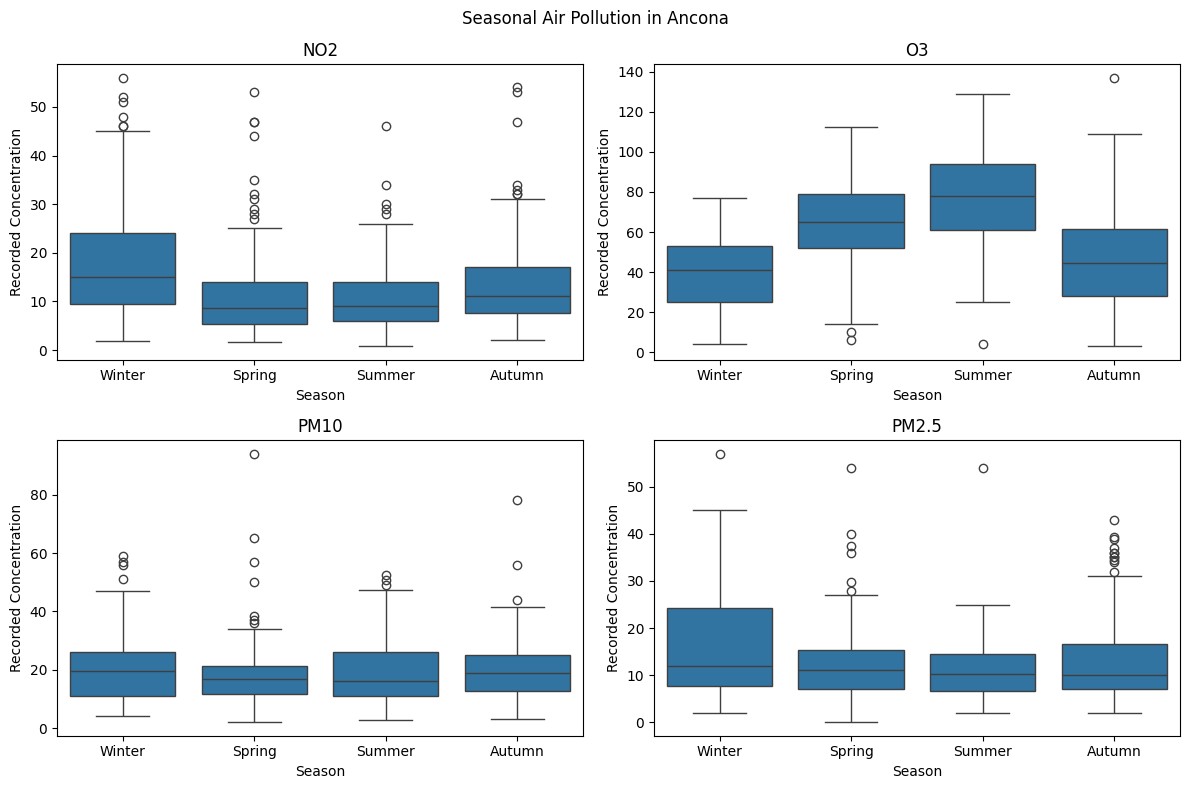

In [11]:

# Create a temporary dataset for seasonal analysis
seasonal = df.copy()

# Extract month from Date
seasonal["Month"] = seasonal["Date"].dt.month

# Identify seasons
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

seasonal["Season"] = seasonal["Month"].apply(get_season)

# Define season order
seasons = ["Winter", "Spring", "Summer", "Autumn"]

# Calculate seasonal averages
season_avg = seasonal.groupby("Season")[pollutants].mean()
display(season_avg.reindex(seasons).round(2))

# Create four seasonal boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, pollutant in zip(axes.flat, pollutants):
    sns.boxplot(
        data=seasonal,
        x="Season",
        y=pollutant,
        order=seasons,
        ax=ax
    )

    ax.set_title(pollutant)
    ax.set_xlabel("Season")
    ax.set_ylabel("Recorded Concentration")

plt.suptitle("Seasonal Air Pollution in Ancona")
plt.tight_layout()
plt.show()



### Graph 2 — Interpretation

The results show that different pollutants have different seasonal patterns.

- Ozone (O3) had its highest average concentration in summer (77.08).
- NO2 had its highest average concentration in winter (17.82).
- PM10 had its highest average concentration in winter (20.76).
- PM2.5 had its highest average concentration in winter (15.83).

**Public Health Link:** Higher ozone levels during summer and higher particulate pollution during winter suggest that different seasons may require different monitoring priorities.

These findings describe environmental measurements, not confirmed health effects.


## 8. Diagnostic Question


## Research Question 3 — Weather and Air Pollution

**Research Question:** How are humidity, rainfall and wind speed related to air pollutant concentrations?

### Graph 3 — Correlation Heatmap

**Why this graph?**

A correlation heatmap helps us examine the relationships between three weather factors and four air pollutants.

**What does it show?**

The heatmap displays Pearson correlation coefficients between -1 and +1.

- Positive values indicate that two variables tend to increase together.
- Negative values indicate that one variable tends to decrease as the other increases.
- Values close to zero indicate a weak linear relationship.

**Public Health Importance:**

Understanding weather-related pollution patterns can help authorities interpret air-quality changes and improve monitoring strategies.


,NO2,O3,PM10,PM2.5
Relative Humidity,0.16,-0.50,-0.00,0.08
Total Percipitation,-0.08,-0.06,-0.15,-0.11
Wind_Speed,-0.10,0.13,-0.06,-0.07


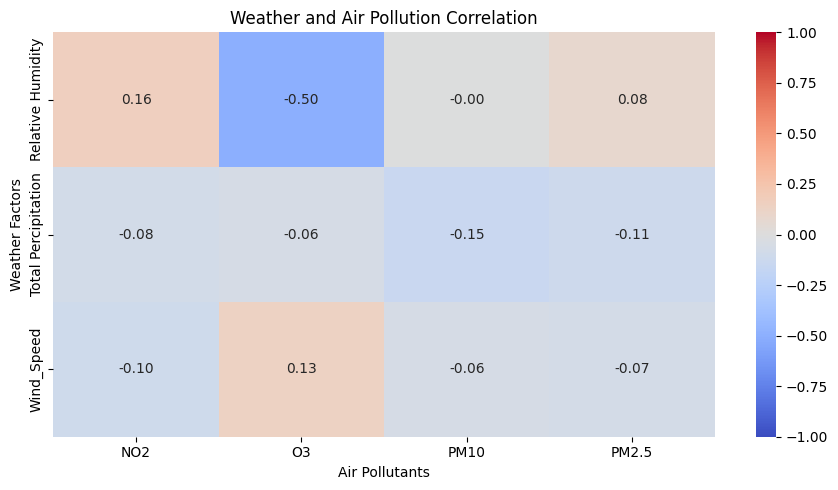

In [13]:

# Create a temporary dataset for weather analysis
weather_df = df.copy()

# Calculate wind speed from U and V components
weather_df["Wind_Speed"] = np.sqrt(
    weather_df["Wind-Speed (U)"]**2 +
    weather_df["Wind-Speed (V)"]**2
)

# Select weather factors
weather = [
    "Relative Humidity",
    "Total Percipitation",
    "Wind_Speed"
]

# Calculate Pearson correlations
correlation = weather_df[
    weather + pollutants
].corr()

# Select weather vs pollutant correlations
result = correlation.loc[weather, pollutants]

display(result.round(2))

# Create correlation heatmap
plt.figure(figsize=(9, 5))

sns.heatmap(
    result,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Weather and Air Pollution Correlation")
plt.xlabel("Air Pollutants")
plt.ylabel("Weather Factors")
plt.tight_layout()
plt.show()



### Graph 3 — Interpretation

The correlation heatmap shows how weather factors are associated with air pollutant concentrations.

The strongest relationship among the displayed weather–pollutant pairs was between relative humidity and ozone (r = -0.50).

This negative correlation indicates that higher humidity was generally associated with lower ozone readings in our dataset.

**Public Health Link:** Weather information may help environmental authorities understand changes in pollution levels and improve air-quality monitoring.

However, correlation does not prove causation.


## 9. Action Questions

## A. Research Question 4 — Monitoring Station Comparison

**Research Question:** Which monitoring stations record higher average NO2 and PM2.5 concentrations?

### Graph 4 — Horizontal Bar Chart

**Why this graph?**

A horizontal bar chart allows us to compare pollutant concentrations across different monitoring stations.

**What does it show?**

It shows the average NO2 and PM2.5 readings at each station and helps identify locations with relatively higher concentrations.

**Public Health Importance:**

Identifying stations with higher pollution readings can help environmental authorities decide where further investigation and monitoring may be needed.


,NO2,PM2.5,Observations
station_name,,,
Falconara Alta,14.14,10.55,56
Ancona CAMS Station 4,9.64,11.64,56
Ancona CAMS Station 2,9.78,11.76,35
Falconara Scuola,21.54,12.26,54
Ancona CAMS Station 5,7.84,12.55,57
Ancona CAMS Station 8,10.00,13.25,57
Ancona CAMS Station 11,7.68,13.30,41
Ancona Citadella,13.51,13.83,47
Ancona Stazione FF,21.20,14.51,49


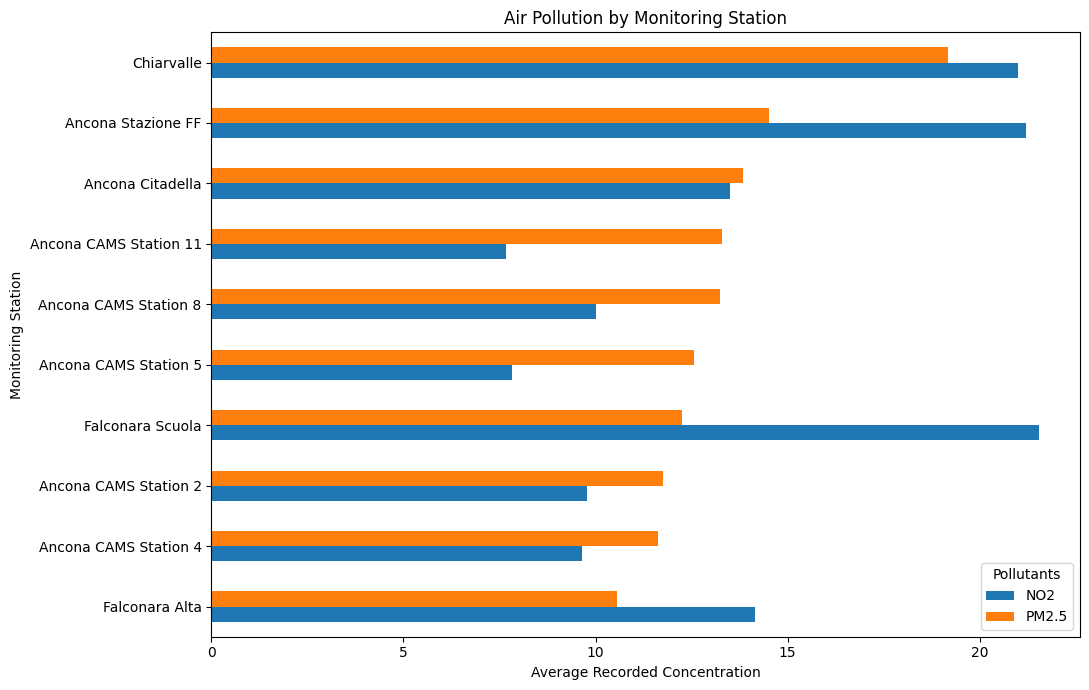

In [14]:

# Calculate average NO2 and PM2.5 by station
station_avg = df.groupby("station_name")[
    ["NO2", "PM2.5"]
].mean()

# Sort stations by PM2.5
station_avg = station_avg.sort_values("PM2.5")

# Count observations at each station
station_count = df.groupby("station_name").size()

# Display station averages and counts
display(
    station_avg.join(
        station_count.rename("Observations")
    ).round(2)
)

# Create horizontal bar chart
station_avg.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.title("Air Pollution by Monitoring Station")
plt.xlabel("Average Recorded Concentration")
plt.ylabel("Monitoring Station")
plt.legend(title="Pollutants")
plt.tight_layout()
plt.show()



### Graph 4 — Interpretation

The analysis shows differences in pollution concentrations between monitoring stations.

Falconara Scuola recorded the highest average NO2 concentration (21.54), while Chiarvalle recorded the highest average PM2.5 concentration (19.17).

**Public Health Link:** These locations may deserve closer monitoring to better understand local pollution patterns.

However, station averages do not directly measure individual exposure or disease risk. Differences in observation counts may also influence the comparison.



## B. Research Question 5 — Monthly Pollution Trends

**Research Question:** How do ozone and PM2.5 concentrations change across the available months?

### Graph 5 — Line Chart

**Why this graph?**

A line chart helps us understand changes in pollutant concentrations over time.

**What does it show?**

It displays the monthly average concentrations of ozone and PM2.5 and helps identify months with higher or lower pollution readings.

**Public Health Importance:**

Monthly trends can help environmental authorities plan seasonal monitoring and public-health awareness activities.


,O3,PM2.5,Observations
Year_Month,,,
2021-09,60.37,12.33,22
2021-10,41.25,7.95,20
2021-11,22.95,15.71,24
2021-12,36.41,18.43,23
2022-01,35.49,20.55,22
2022-02,45.21,12.25,22
2022-03,60.73,16.74,21
2022-04,66.89,8.81,19
2022-05,70.19,13.52,15


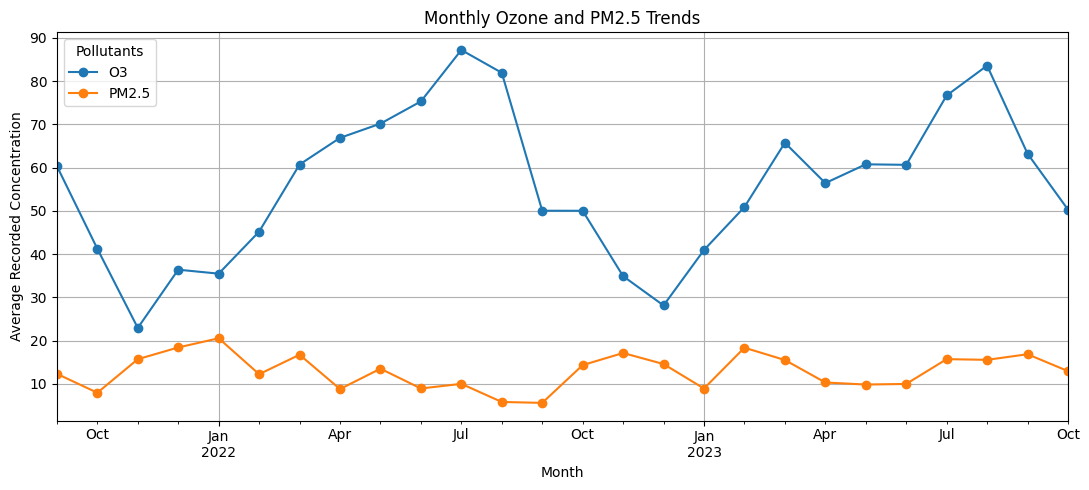

In [15]:

# Create a temporary dataset for monthly analysis
monthly_df = df.copy()

# Extract year and month together
monthly_df["Year_Month"] = (
    monthly_df["Date"].dt.to_period("M")
)

# Calculate monthly averages
monthly = monthly_df.groupby("Year_Month")[
    ["O3", "PM2.5"]
].mean()

# Count observations per month
monthly_count = monthly_df.groupby("Year_Month").size()

# Display monthly averages and counts
display(
    monthly.join(
        monthly_count.rename("Observations")
    ).round(2)
)

# Convert month to date format for plotting
monthly.index = monthly.index.to_timestamp()

# Create line chart
monthly.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

plt.title("Monthly Ozone and PM2.5 Trends")
plt.xlabel("Month")
plt.ylabel("Average Recorded Concentration")
plt.legend(title="Pollutants")
plt.grid(True)
plt.tight_layout()
plt.show()



### Graph 5 — Interpretation

The line chart shows how average ozone and PM2.5 concentrations changed across the available months.

The highest sampled monthly average ozone concentration occurred in July 2022 (87.22).

The highest sampled monthly average PM2.5 concentration occurred in January 2022 (20.55).

**Public Health Link:** These findings can help environmental authorities identify months that may require additional pollution monitoring and public awareness activities.

However, the dataset does not contain continuous daily measurements. Therefore, the graph represents trends within our available observations.



## 11. Key Findings, Stakeholder Recommendations and Conclusion

### 11.1 Key Findings

Our analysis of 500 air-quality observations from Ancona, Italy, identified five important patterns related to time, season, weather conditions and monitoring locations.

**1. Morning vs Evening Pollution**

Average ozone (O3) concentration was higher at 5 PM (73.50) than at 8 AM (49.53). This difference may be related to sunlight-driven ozone formation during the day. However, the unequal number of observations (60 at 8 AM and 8 at 5 PM) limits the reliability of this comparison.

**2. Seasonal Pollution Patterns**

Summer recorded the highest average O3 concentration (77.08), while winter recorded the highest average NO2 (17.82), PM10 (20.76) and PM2.5 (15.83).

Strong summer sunlight may support ozone formation, while reduced atmospheric mixing during winter may contribute to the accumulation of other pollutants.

**3. Weather and Air Pollution**

Relative humidity showed a moderate negative correlation with O3 (r = -0.50), indicating that higher humidity was generally associated with lower ozone concentrations in our dataset.

Weather conditions may influence pollutant formation and dispersion, although this relationship does not establish causation.

**4. Monitoring Station Differences**

Falconara Scuola recorded the highest average NO2 concentration (21.54), while Chiarvalle recorded the highest average PM2.5 concentration (19.17).

These differences may be influenced by local emission sources, traffic or environmental conditions. Further investigation is needed to identify the actual causes.

**5. Monthly Pollution Trends**

The highest sampled monthly average O3 concentration occurred in July 2022 (87.22), while PM2.5 reached its highest sampled monthly average in January 2022 (20.55).

These findings suggest that different pollutants may require closer attention during different periods of the year.

---

### 11.2 Stakeholder Action Plan

Based on our findings, we propose the following evidence-based recommendations to support environmental monitoring and public-health planning.

| Key Finding | Recommended Action | Responsible Stakeholder |
|---|---|---|
| **Morning vs Evening:** Higher average O3 was observed at 5 PM, but the sample sizes were unequal. | Collect more balanced hourly measurements and investigate afternoon ozone patterns before introducing time-specific alerts. | Environmental Monitoring Agencies |
| **Seasonal Pollution:** O3 was highest in summer, while NO2, PM10 and PM2.5 were highest in winter. | Prioritize ozone monitoring during summer and NO2 and particulate matter monitoring during winter. | Regional Environmental Agencies and Local Government |
| **Weather and Pollution:** Relative humidity showed a negative correlation with O3 (r = -0.50). | Combine weather information with air-quality monitoring to better understand pollution variations. | Environmental Researchers and Meteorological Agencies |
| **Monitoring Stations:** Falconara Scuola had the highest average NO2, while Chiarvalle had the highest average PM2.5. | Investigate possible local emission sources and strengthen monitoring at stations with higher pollutant readings. | Local Environmental Authorities and Municipal Government |
| **Monthly Trends:** O3 was highest in July 2022, while PM2.5 was highest in January 2022 within the sample. | Review monthly pollution patterns and plan seasonal awareness activities when pollution levels are elevated. | Public Health Departments and Environmental Agencies |

### 11.3 Expected Public Health Value

Our analysis can support public-health planning in several ways:

- **Better Monitoring:** Identify seasons, times and locations that may require closer air-quality monitoring.
- **Early Awareness:** Support timely communication about elevated pollution levels.
- **Protection of Vulnerable Groups:** Help public-health authorities communicate relevant precautions to children, older adults and people with respiratory or cardiovascular conditions.
- **Evidence-Based Decisions:** Support coordination between environmental agencies, researchers and public-health departments.

These are potential applications of our findings rather than health outcomes directly measured in the dataset.

---

### 11.4 Limitations and Future Research

**1. Limited Dataset**

Our analysis uses 500 observations rather than continuous hourly and daily measurements. Therefore, the results may not represent all pollution conditions in Ancona.

**2. Unequal Time-Based Observations**

The dataset contains 60 observations at 8 AM and only 8 at 5 PM. This limits our ability to establish reliable morning-versus-evening pollution patterns.

**3. No Hospital or Patient Data**

Our dataset contains environmental measurements but does not include hospital admissions, medical diagnoses or patient ages.

If hospital data were available, future research could investigate:

- Whether higher pollution periods are associated with increased respiratory or cardiovascular hospital visits.
- Which health conditions, such as asthma or respiratory infections, are more frequently reported during highly polluted periods.
- Which age groups, including children, adults and older people, are more affected.

Such research could provide a clearer understanding of the relationship between air pollution and public health.

**4. No Individual Exposure Data**

Monitoring-station measurements cannot determine how much pollution each individual inhales.

**5. Correlation Does Not Establish Causation**

The relationships identified between weather conditions and air pollution do not prove that one variable directly causes another.

**6. Measurement Limitations**

Pollutant measurement units and averaging periods should be verified before comparing the findings with official air-quality guidelines.

---

### 11.5 Conclusion

This project demonstrates how Python, ETL and data visualization can transform environmental measurements into meaningful insights for air-quality monitoring.

Our findings highlight important differences in pollution concentrations across times of day, seasons, weather conditions, monitoring stations and months.

The analysis suggests that ozone deserves additional monitoring attention during summer, while NO2 and particulate matter require closer attention during winter.

By connecting these findings with practical stakeholder recommendations, our project goes beyond describing pollution patterns and identifies opportunities for evidence-based environmental and public-health planning.

Although the dataset does not directly measure health outcomes or establish the causes of pollution, it provides a useful foundation for future research combining environmental and healthcare data.
